X_train: (240, 64, 64), y_train: (240,)
X_val:   (80, 64, 64), y_val:   (80,)
X_test:  (80, 64, 64), y_test:  (80,)
X_test_corrupted:  (80, 64, 64), y_test:  (80,)
Boosting | Learner:25 | B_Train Acc:0.2792 | B_Val Acc:0.1000 | B_Test Acc0.1875 | Time (s):17.485
Bagging | Learner:25 | Bag_Train Acc:1.0000 | Bag_Val Acc:0.7875 | Bag_Test Acc0.8000 | Time (s):88.840
Boosting | Learner:50 | B_Train Acc:0.8000 | B_Val Acc:0.3125 | B_Test Acc0.3375 | Time (s):34.894
Bagging | Learner:50 | Bag_Train Acc:1.0000 | Bag_Val Acc:0.8000 | Bag_Test Acc0.8250 | Time (s):165.496
Boosting | Learner:100 | B_Train Acc:0.9500 | B_Val Acc:0.4250 | B_Test Acc0.4500 | Time (s):82.849
Bagging | Learner:100 | Bag_Train Acc:1.0000 | Bag_Val Acc:0.8375 | Bag_Test Acc0.8500 | Time (s):415.879

BEST MODEL SELECTION SUMMARY (BASED ON VALIDATION ACCURACY)
Boosting Best L: 100 | Best Validation Accuracy: 0.4250
Bagging  Best L: 100 | Best Validation Accuracy: 0.8375
HARD SAMPLE INSPECTION (Sample Index: 0)
Final Rou

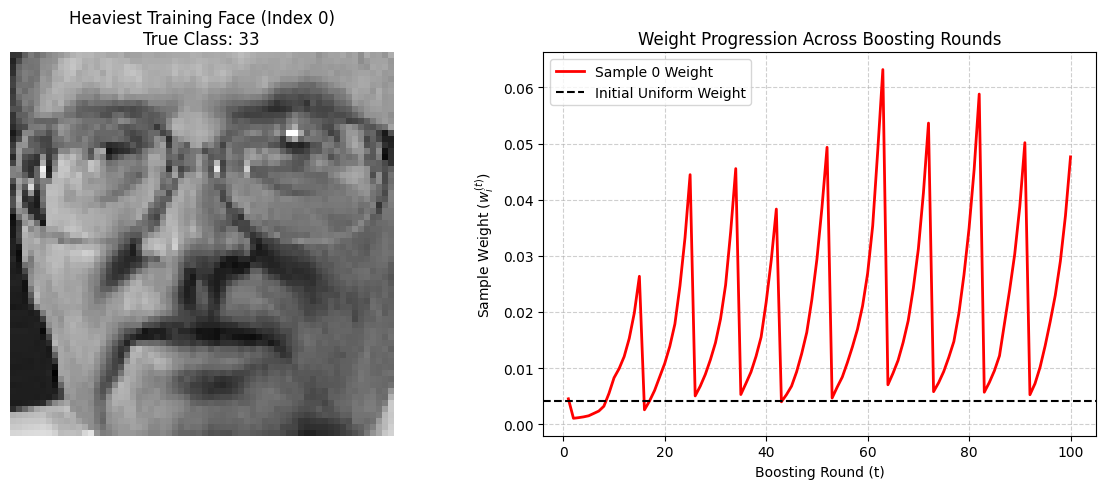

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q2_c.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

faces = fetch_olivetti_faces(shuffle=False)
X = faces.images
y = faces.target

height = X.shape[1]
width = X.shape[2]

split_data = np.load("olivetti_split_indices.npz")

train_idx = split_data["train"]
val_idx = split_data["val"]
test_idx = split_data["test"]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_test_corrupted = X_test.copy()
X_test_corrupted[:, 24:40, 24:40] = 0.0

logger.info(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
logger.info(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
logger.info(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
logger.info(f"X_test_corrupted:  {X_test_corrupted.shape}, y_test:  {y_test.shape}")




X_train = X_train.reshape(-1, height * width)
X_val = X_val.reshape(-1, height * width)
X_test = X_test.reshape(-1, height * width)
X_test_corrupted = X_test_corrupted.reshape(-1, height * width)

seed = 260007
n_train = len(X_train)

def fit_samme_adaboost(X_flat, y, n_estimators, max_depth):

    N = len(y)
    classes = np.unique(y)
    K = len(classes)
    top_k = 10

    w = np.ones(N, dtype=np.float64) / N

    estimators = []
    estimator_weights = []

    history = {
        "eps_ts": [],
        "alphas": [],
        "max_sample_weights": [],
        "top10_weights": [],
        "sample_weights_over_time": []
    }
    
    for t in range(n_estimators):
        clf = DecisionTreeClassifier(max_depth=max_depth, random_state=seed + t)
        clf.fit(X_flat, y, sample_weight=w)

        preds = clf.predict(X_flat)
        incorrect = (preds != y)

        eps_t = np.sum(w * incorrect) / np.sum(w)

        random_guess_error = 1.0 - (1.0 / K)
        if eps_t >= random_guess_error:
            if t == 0:
                alpha_t = 1e-10
                estimators.append(clf)
                estimator_weights.append(alpha_t)
            break

        if eps_t == 0:
            alpha_t = 100.0
        else:
            alpha_t = np.log((1.0 - eps_t) / eps_t) + np.log(K - 1)

        w_updated = w * np.exp(alpha_t * incorrect)

        w_next = w_updated / np.sum(w_updated)

        estimators.append(clf)
        estimator_weights.append(alpha_t)

        history["eps_ts"].append(eps_t)
        history["alphas"].append(alpha_t)
        history["max_sample_weights"].append(np.max(w_next))
        
        history["top10_weights"].append(np.sum(np.sort(w_next)[-top_k:]))
        history["sample_weights_over_time"].append(w_next.copy())

        w = w_next

    return estimators, estimator_weights, classes, history

def predict_samme(X_flat, estimators, estimator_weights, classes):
    N = len(X_flat)
    K = len(classes)
    scores = np.zeros((N, K))

    for clf, alpha in zip(estimators, estimator_weights):
        preds = clf.predict(X_flat)
        for k_idx, c in enumerate(classes):
            scores[:, k_idx] += alpha * (preds == c)

    best_indices = np.argmax(scores, axis=1)
    return classes[best_indices]

def fit_and_predict_bagging(X_tr, y_tr, X_v, X_te, n_estimators, min_samples_leaf_bag, max_depth_bag):
    trees = []
    tr_preds_matrix = []
    val_preds_matrix = []
    test_preds_matrix = []

    rng = np.random.default_rng(seed=seed)

    for b in range(n_estimators):
        bootstrap_indices = rng.choice(len(X_tr), size=len(X_tr), replace=True)
        X_boot, y_boot = X_tr[bootstrap_indices], y_tr[bootstrap_indices]

        clf = DecisionTreeClassifier(max_depth=max_depth_bag, min_samples_leaf=min_samples_leaf_bag, random_state=seed)
        clf.fit(X_boot, y_boot)
        trees.append(clf)

        tr_preds_matrix.append(clf.predict(X_tr))
        val_preds_matrix.append(clf.predict(X_v))
        test_preds_matrix.append(clf.predict(X_te))

    return tr_preds_matrix, val_preds_matrix, test_preds_matrix

def majority_vote(preds_list):
    mat = np.array(preds_list)
    N_samples = mat.shape[1]
    votes = np.zeros(N_samples, dtype=int)
    for i in range(N_samples):
        cls, counts = np.unique(mat[:, i], return_counts=True)
        votes[i] = cls[np.argmax(counts)]
    return votes

learner_counts = [25, 50, 100]
boosting_depth = 3
max_depth_bag = None
min_samples_leaf_bag = 2

logger.info("=" * 90)

boosting_histories = {}
boost_val_accs = []
bag_val_accs = []

for L in learner_counts:
    t0 = time.time()
    b_estimators, b_weights, classes, b_hist = fit_samme_adaboost(
        X_train, y_train, n_estimators=L, max_depth=boosting_depth
    )
    t_boost = time.time() - t0

    b_tr_pred = predict_samme(X_train, b_estimators, b_weights, classes)
    b_v_pred = predict_samme(X_val, b_estimators, b_weights, classes)
    b_te_pred = predict_samme(X_test, b_estimators, b_weights, classes)

    b_tr_acc = np.mean(b_tr_pred == y_train)
    b_v_acc = np.mean(b_v_pred == y_val)
    b_te_acc = np.mean(b_te_pred == y_test)

    boost_val_accs.append(b_v_acc)
    boosting_histories[L] = (b_estimators, b_weights, b_hist)

    logger.info(f"{'Boosting'} | Learner:{L} | B_Train Acc:{b_tr_acc:.4f} | B_Val Acc:{b_v_acc:.4f} | B_Test Acc{b_te_acc:.4f} | Time (s):{t_boost:.3f}")

    t0 = time.time()
    tr_preds_matrix, val_preds_matrix, test_preds_matrix = fit_and_predict_bagging(
        X_train, y_train, X_val, X_test, n_estimators=L, min_samples_leaf_bag=min_samples_leaf_bag, max_depth_bag=max_depth_bag
    )
    t_bag = time.time() - t0

    bag_tr_pred = majority_vote(tr_preds_matrix)
    bag_v_pred = majority_vote(val_preds_matrix)
    bag_te_pred = majority_vote(test_preds_matrix)

    bag_tr_acc = np.mean(bag_tr_pred == y_train)
    bag_v_acc = np.mean(bag_v_pred == y_val)
    bag_te_acc = np.mean(bag_te_pred == y_test)

    bag_val_accs.append(bag_v_acc)

    logger.info(f"{'Bagging'} | Learner:{L} | Bag_Train Acc:{bag_tr_acc:.4f} | Bag_Val Acc:{bag_v_acc:.4f} | Bag_Test Acc{bag_te_acc:.4f} | Time (s):{t_bag:.3f}")

logger.info("=" * 90 + "\n")

best_boost_idx = np.argmax(boost_val_accs)
best_boost_L = learner_counts[best_boost_idx]
best_boost_val_acc = boost_val_accs[best_boost_idx]

best_bag_idx = np.argmax(bag_val_accs)
best_bag_L = learner_counts[best_bag_idx]
best_bag_val_acc = bag_val_accs[best_bag_idx]

logger.info("=" * 65)
logger.info("BEST MODEL SELECTION SUMMARY (BASED ON VALIDATION ACCURACY)")
logger.info("=" * 65)
logger.info(f"Boosting Best L: {best_boost_L} | Best Validation Accuracy: {best_boost_val_acc:.4f}")
logger.info(f"Bagging  Best L: {best_bag_L} | Best Validation Accuracy: {best_bag_val_acc:.4f}")
logger.info("=" * 65)

estimators_best_boost_L, weights_best_boost_L, hist_best_boost_L = boosting_histories[best_boost_L]
weights_over_time = np.array(hist_best_boost_L["sample_weights_over_time"])

final_round_weights = weights_over_time[-1]
heaviest_idx = np.argmax(final_round_weights)
max_weight_val = final_round_weights[heaviest_idx]
true_label = y_train[heaviest_idx]

logger.info("=" * 70)
logger.info(f"HARD SAMPLE INSPECTION (Sample Index: {heaviest_idx})")
logger.info(f"Final Round Weight: {max_weight_val:.6f} (Initial weight was {1.0/n_train:.6f})")
logger.info(f"True Class Label:   {true_label}")
logger.info("=" * 70)

sample_preds = [clf.predict(X_train[heaviest_idx:heaviest_idx+1])[0] for clf in estimators_best_boost_L]
misclassified_rounds = [t + 1 for t, pred in enumerate(sample_preds) if pred != true_label]

num_misclassified = len(misclassified_rounds)
logger.info(f"Misclassified in {num_misclassified} / {len(estimators_best_boost_L)} boosting rounds.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow((X_train.reshape(-1, height, width) * 255).astype(np.uint8)[heaviest_idx], cmap="gray")
axes[0].set_title(f"Heaviest Training Face (Index {heaviest_idx})\nTrue Class: {true_label}")
axes[0].axis("off")

rounds_axis = np.arange(1, len(weights_over_time) + 1)
axes[1].plot(rounds_axis, weights_over_time[:, heaviest_idx], color="red", linewidth=2, label=f"Sample {heaviest_idx} Weight")
axes[1].axhline(y=1.0/n_train, color="black", linestyle="--", label="Initial Uniform Weight")
axes[1].set_xlabel("Boosting Round (t)")
axes[1].set_ylabel("Sample Weight ($w_i^{(t)}$)")
axes[1].set_title("Weight Progression Across Boosting Rounds")
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()

plt.savefig("q2_c_boost_metrics.png", dpi=300, bbox_inches="tight")

plt.show()

In [2]:
estimators_best_boost_L, weights_best_boost_L, hist_best_boost_L = boosting_histories[best_boost_L]
weights_over_time = np.array(hist_best_boost_L["sample_weights_over_time"])

final_round_weights = weights_over_time[-1]
heaviest_idx = np.argmax(final_round_weights)
max_weight_val = final_round_weights[heaviest_idx]
true_label = y_train[heaviest_idx]

sample_preds = [clf.predict(X_train[heaviest_idx:heaviest_idx+1])[0] for clf in estimators_best_boost_L]
alphas = weights_best_boost_L
epsilons = hist_best_boost_L["eps_ts"]

logger.info("\n" + "="*80)
logger.info(f"HARD SAMPLE DIAGNOSTICS (Index: {heaviest_idx} | True Label: {true_label})")
logger.info("="*80)
logger.info(f"Initial Weight:{1.0/n_train:.6f}")
logger.info(f"Final Round Weight:{max_weight_val:.6f} (Factor of {max_weight_val * n_train:.2f}x higher)")

misclassified_indices = [t for t, pred in enumerate(sample_preds) if pred != true_label]
correct_indices = [t for t, pred in enumerate(sample_preds) if pred == true_label]

logger.info(f"Total Rounds:{len(estimators_best_boost_L)}")
logger.info(f"Misclassified Rounds:{len(misclassified_indices)} / {len(estimators_best_boost_L)} ({len(misclassified_indices)/len(estimators_best_boost_L)*100:.1f}%)")
logger.info(f"Correctly Classified In:{len(correct_indices)} / {len(estimators_best_boost_L)} ({len(correct_indices)/len(estimators_best_boost_L)*100:.1f}%)")

pred_classes, pred_counts = np.unique(sample_preds, return_counts=True)
logger.info("\n--- Prediction Frequency Breakdown Across Rounds ---")
for cls, count in zip(pred_classes, pred_counts):
    status = "TRUE LABEL" if cls == true_label else "CONFUSED WITH"
    logger.info(f"  Class {cls:2d} ({status}): {count:2d} times ({count/len(sample_preds)*100:.1f}%)")

logger.info("\n--- Step-by-Step Weight Mechanics (First 10 Rounds) ---")
logger.info(f"{'Round (t)':<10} | {'Pred Class':<10} | {'Correct?':<10} | {'Error (eps_t)':<15} | {'Alpha_t':<10} | {'New Weight':<12}")
logger.info("-" * 75)
for t in range(min(10, len(estimators_best_boost_L))):
    pred = sample_preds[t]
    is_correct = (pred == true_label)
    w_val = weights_over_time[t, heaviest_idx]
    eps = epsilons[t]
    alp = alphas[t]
    logger.info(f"{t+1:<10} | {pred:<10} | {str(is_correct):<10} | {eps:<15.4f} | {alp:<10.4f} | {w_val:<12.6f}")

logger.info("="*80 + "\n")


HARD SAMPLE DIAGNOSTICS (Index: 0 | True Label: 33)
Initial Weight:0.004167
Final Round Weight:0.047622 (Factor of 11.43x higher)
Total Rounds:100
Misclassified Rounds:90 / 100 (90.0%)
Correctly Classified In:10 / 100 (10.0%)

--- Prediction Frequency Breakdown Across Rounds ---
  Class  0 (CONFUSED WITH):  2 times (2.0%)
  Class  1 (CONFUSED WITH):  7 times (7.0%)
  Class  2 (CONFUSED WITH):  4 times (4.0%)
  Class  3 (CONFUSED WITH):  4 times (4.0%)
  Class  4 (CONFUSED WITH):  8 times (8.0%)
  Class  6 (CONFUSED WITH):  1 times (1.0%)
  Class  9 (CONFUSED WITH):  1 times (1.0%)
  Class 12 (CONFUSED WITH):  5 times (5.0%)
  Class 14 (CONFUSED WITH):  7 times (7.0%)
  Class 15 (CONFUSED WITH):  3 times (3.0%)
  Class 16 (CONFUSED WITH):  8 times (8.0%)
  Class 17 (CONFUSED WITH):  7 times (7.0%)
  Class 20 (CONFUSED WITH):  7 times (7.0%)
  Class 22 (CONFUSED WITH):  5 times (5.0%)
  Class 24 (CONFUSED WITH):  3 times (3.0%)
  Class 25 (CONFUSED WITH):  4 times (4.0%)
  Class 26 (CON